# Loan Approval Classification — End-to-End Case Study

**Dataset:** `loan_approval_dataset.csv`  
**Task:** Binary Classification (`Approved` vs `Rejected`)  

### 15-Step Workflow
1. **Load** — Load dataset and libraries  
2. **Inspect** — Check shape, types, missing values, duplicates, and anomalies  
3. **Clean** — Strip whitespace, drop ID column, fix negative asset values  
4. **Feature Engineering** — Create domain ratios & total asset features  
5. **EDA** — Visualize target balance, distributions, and correlations  
6. **Define Target / Labels** — Encode `loan_status` (`Approved=1`, `Rejected=0`)  
7. **Split** — Stratified 80/20 Train-Test split  
8. **Preprocess** — Build leakage-free `ColumnTransformer` pipeline  
9. **Train** — Train 4 classification models (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting)  
10. **Predict** — Generate class labels and probabilities on the test set  
11. **Evaluate** — Compare Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix, and ROC Curves  
12. **Interpret** — Feature Importance & Permutation Importance  
13. **Validate** — 5-Fold Stratified Cross-Validation & Overfitting Check  
14. **Save Artifacts** — Persist best pipeline (`joblib`), metadata (`json`), and predictions (`csv`)  
15. **Demo Prediction** — Reload saved model and predict on new applicant profiles

## Step 1: Load
Import required libraries and load `loan_approval_dataset.csv`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100

# Load dataset
DATA_PATH = 'loan_approval_dataset.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully! Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Dataset loaded successfully! Shape: 4,269 rows x 13 columns


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Step 2: Inspect
Examine raw column names, data types, missing values, duplicates, summary statistics, and potential anomalies.

In [2]:
print("1. Raw Column Names (notice leading spaces!):")
print([repr(c) for c in df_raw.columns])

print("\n2. Data Types & Non-Null Counts:")
print(df_raw.dtypes)

print("\n3. Missing Values per Column:")
print(df_raw.isnull().sum())

print(f"\n4. Duplicate Rows: {df_raw.duplicated().sum()}")

print("\n5. Unique Values in Categorical Columns (notice leading spaces!):")
for col in df_raw.select_dtypes(include='object').columns:
    print(f"   {repr(col)}: {df_raw[col].unique().tolist()}")

print("\n6. Check for Negative Values in Numeric Columns:")
for col in df_raw.select_dtypes(include='number').columns:
    neg_cnt = (df_raw[col] < 0).sum()
    if neg_cnt > 0:
        print(f"   {repr(col)}: {neg_cnt} negative rows (min = {df_raw[col].min()})")

print("\n7. Summary Statistics (Numeric):")
print(df_raw.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

1. Raw Column Names (notice leading spaces!):
["'loan_id'", "' no_of_dependents'", "' education'", "' self_employed'", "' income_annum'", "' loan_amount'", "' loan_term'", "' cibil_score'", "' residential_assets_value'", "' commercial_assets_value'", "' luxury_assets_value'", "' bank_asset_value'", "' loan_status'"]

2. Data Types & Non-Null Counts:
loan_id                       int64
 no_of_dependents             int64
 education                   object
 self_employed               object
 income_annum                 int64
 loan_amount                  int64
 loan_term                    int64
 cibil_score                  int64
 residential_assets_value     int64
 commercial_assets_value      int64
 luxury_assets_value          int64
 bank_asset_value             int64
 loan_status                 object
dtype: object

3. Missing Values per Column:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_ann

## Step 3: Clean
Based on our inspection, we perform four cleaning steps:
1. Strip leading/trailing spaces from all column names.
2. Strip leading/trailing spaces from all string/categorical values.
3. Drop the non-predictive identifier column `loan_id`.
4. Clip negative `residential_assets_value` entries (28 rows with `-100,000`) to `0`, as physical asset values cannot be negative.

In [3]:
df = df_raw.copy()

# 1. Strip whitespace from column names
df.columns = df.columns.str.strip()

# 2. Strip whitespace from string values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# 3. Drop identifier column
if 'loan_id' in df.columns:
    df = df.drop(columns=['loan_id'])

# 4. Fix negative values in residential_assets_value
neg_before = (df['residential_assets_value'] < 0).sum()
df['residential_assets_value'] = df['residential_assets_value'].clip(lower=0)
neg_after = (df['residential_assets_value'] < 0).sum()

print(f"Cleaned columns ({len(df.columns)}): {df.columns.tolist()}")
print(f"Negative residential_assets_value: {neg_before} -> {neg_after}")
print(f"Cleaned shape: {df.shape}")
for col in df.select_dtypes(include='object').columns:
    print(f"   {col}: {df[col].unique().tolist()}")

Cleaned columns (12): ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']
Negative residential_assets_value: 28 -> 0
Cleaned shape: (4269, 12)
   education: ['Graduate', 'Not Graduate']
   self_employed: ['No', 'Yes']
   loan_status: ['Approved', 'Rejected']


## Step 4: Feature Engineering
Create domain-specific financial features that help classifiers assess borrower creditworthiness:
- **`total_assets_value`**: Sum of residential, commercial, luxury, and bank assets.
- **`loan_to_income_ratio`**: Ratio of requested loan amount to annual income.
- **`loan_to_assets_ratio`**: Ratio of requested loan amount to total assets.
- **`annual_loan_burden`**: Approximate annual principal repayment (`loan_amount / loan_term`).
- **`emi_to_income_ratio`**: Annual loan burden relative to annual income.
- **`cibil_category`**: Standard credit score tier (`Poor`, `Fair`, `Good`, `Excellent`).

In [4]:
def add_engineered_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d['total_assets_value'] = (
        d['residential_assets_value']
        + d['commercial_assets_value']
        + d['luxury_assets_value']
        + d['bank_asset_value']
    )
    d['loan_to_income_ratio'] = d['loan_amount'] / (d['income_annum'] + 1)
    d['loan_to_assets_ratio'] = d['loan_amount'] / (d['total_assets_value'] + 1)
    d['annual_loan_burden'] = d['loan_amount'] / d['loan_term']
    d['emi_to_income_ratio'] = d['annual_loan_burden'] / (d['income_annum'] + 1)
    d['cibil_category'] = pd.cut(
        d['cibil_score'],
        bins=[0, 549, 649, 749, 950],
        labels=['Poor', 'Fair', 'Good', 'Excellent']
    ).astype(str)
    return d

df = add_engineered_features(df)

engineered_cols = [
    'total_assets_value', 'loan_to_income_ratio', 'loan_to_assets_ratio',
    'annual_loan_burden', 'emi_to_income_ratio', 'cibil_category'
]
print("Engineered features added successfully! New shape:", df.shape)
print(df[engineered_cols].head())

Engineered features added successfully! New shape: (4269, 18)
   total_assets_value  loan_to_income_ratio  loan_to_assets_ratio  annual_loan_burden  emi_to_income_ratio cibil_category
0            50700000              3.114583              0.589744        2.491667e+06             0.259549      Excellent
1            17000000              2.975609              0.717647        1.525000e+06             0.371951           Poor
2            57700000              3.263736              0.514731        1.485000e+06             0.163187           Poor
3            52700000              3.743902              0.582543        3.837500e+06             0.467988           Poor
4            55000000              2.469388              0.440000        1.210000e+06             0.123469           Poor


## Step 5: EDA (Exploratory Data Analysis)
Explore target class balance, key numerical feature distributions by loan status, categorical approval rates, and feature correlations.

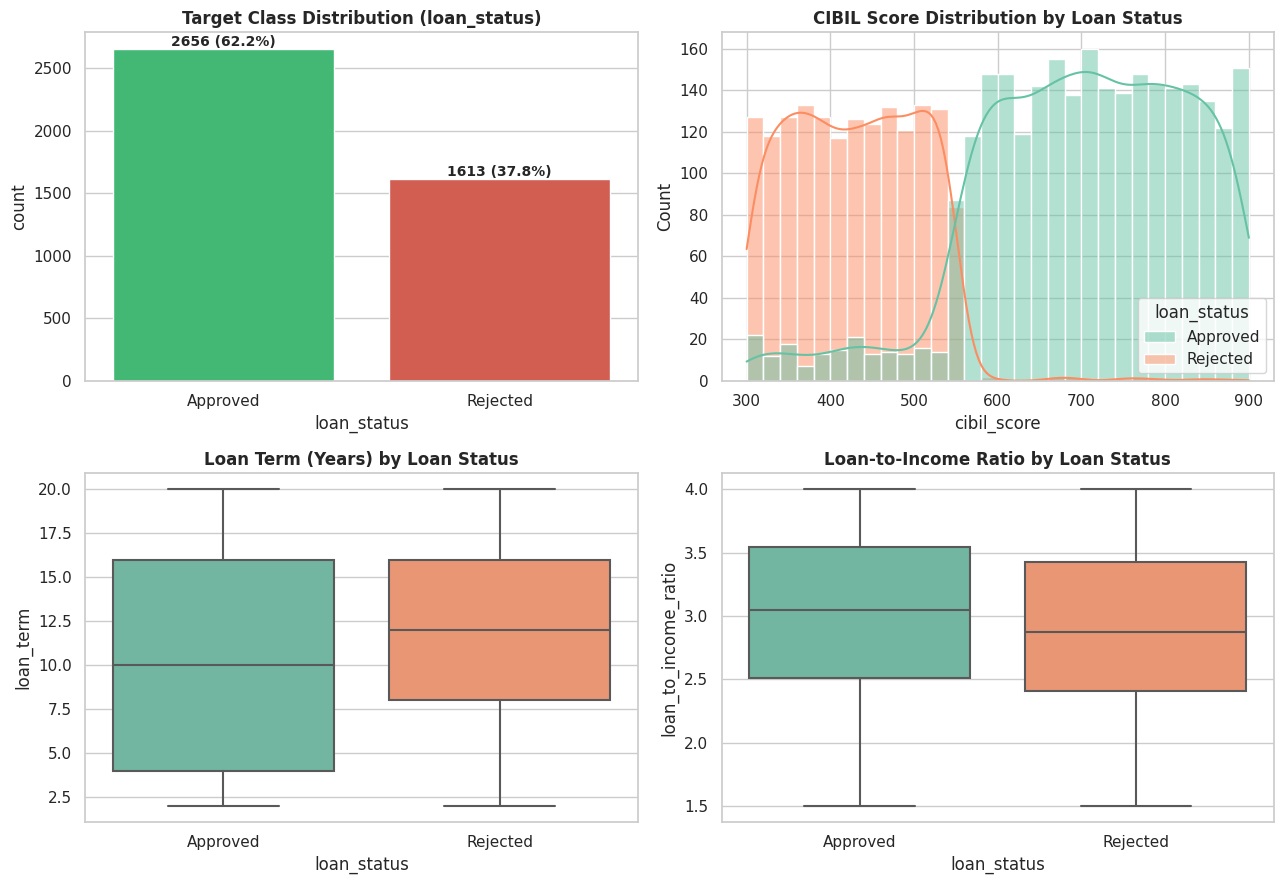

In [5]:
# 5.1 Target distribution and key numeric features by loan_status
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Target countplot
sns.countplot(data=df, x='loan_status', ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Target Class Distribution (loan_status)', fontweight='bold')
for p in axes[0, 0].patches:
    pct = 100 * p.get_height() / len(df)
    axes[0, 0].annotate(f"{int(p.get_height())} ({pct:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=10, fontweight='bold')

# CIBIL Score vs Loan Status
sns.histplot(data=df, x='cibil_score', hue='loan_status', kde=True, bins=30, ax=axes[0, 1])
axes[0, 1].set_title('CIBIL Score Distribution by Loan Status', fontweight='bold')

# Loan Term vs Loan Status
sns.boxplot(data=df, x='loan_status', y='loan_term', ax=axes[1, 0])
axes[1, 0].set_title('Loan Term (Years) by Loan Status', fontweight='bold')

# Loan-to-Income Ratio vs Loan Status
sns.boxplot(data=df, x='loan_status', y='loan_to_income_ratio', ax=axes[1, 1])
axes[1, 1].set_title('Loan-to-Income Ratio by Loan Status', fontweight='bold')

plt.tight_layout()
plt.show()

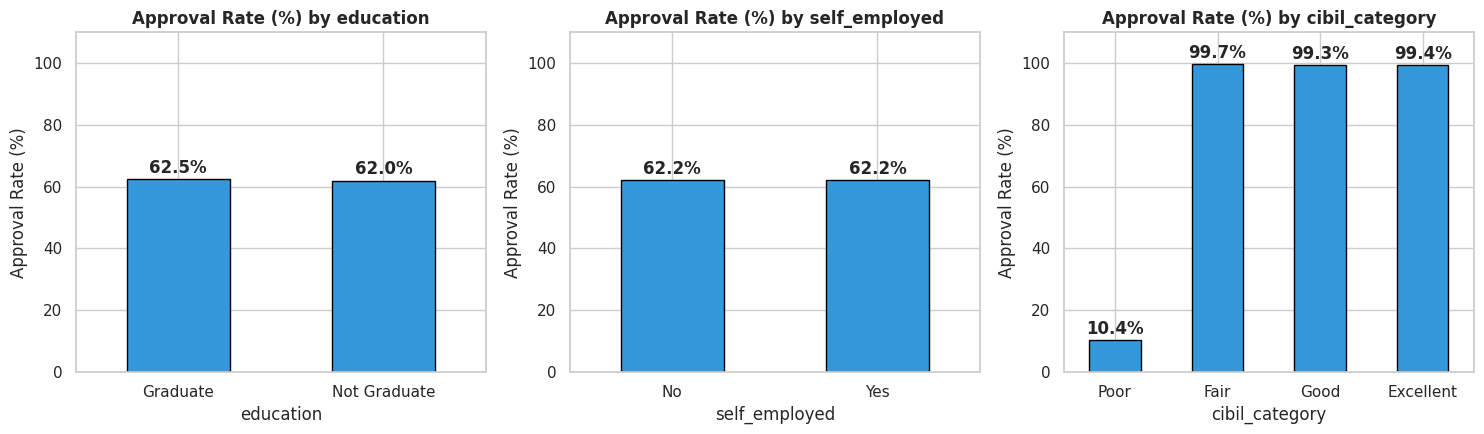

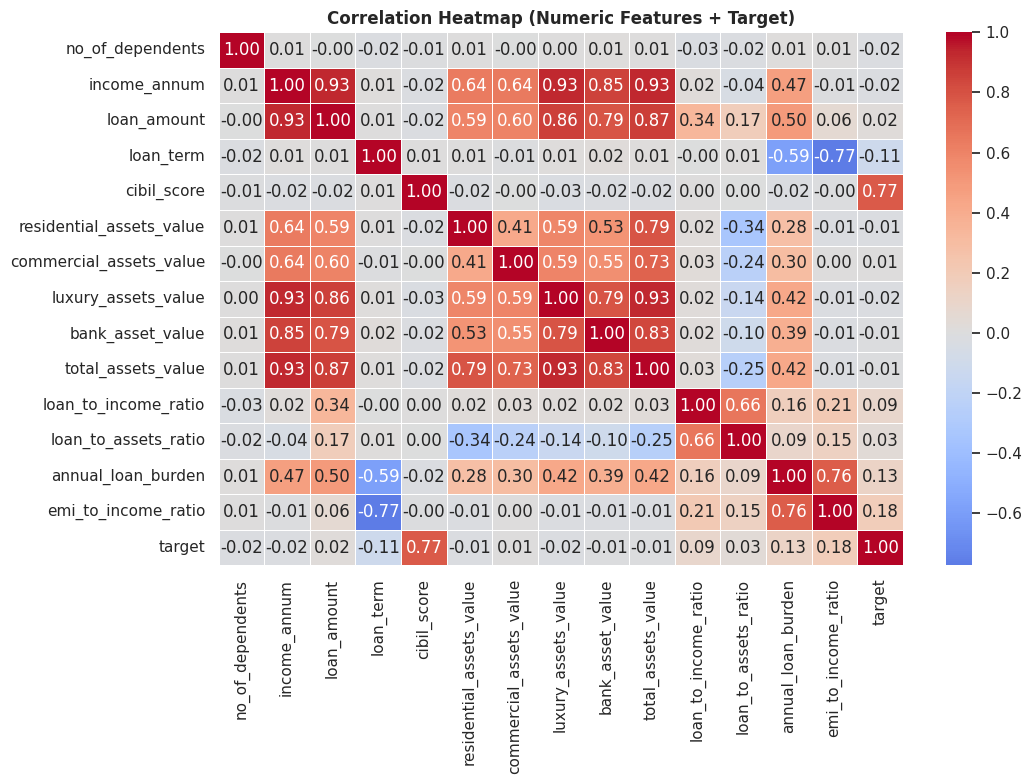

In [6]:
# 5.2 Approval Rate by Categorical Features & Correlation Heatmap
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ['education', 'self_employed', 'cibil_category']):
    order = ['Poor', 'Fair', 'Good', 'Excellent'] if col == 'cibil_category' else None
    rate = df.groupby(col)['loan_status'].apply(lambda s: (s == 'Approved').mean() * 100)
    if order:
        rate = rate.reindex(order)
    rate.plot(kind='bar', ax=ax, color='#3498db', edgecolor='black')
    ax.set_title(f'Approval Rate (%) by {col}', fontweight='bold')
    ax.set_ylabel('Approval Rate (%)')
    ax.set_ylim(0, 110)
    ax.tick_params(axis='x', rotation=0)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Correlation Heatmap
df_corr = df.copy()
df_corr['target'] = (df_corr['loan_status'] == 'Approved').astype(int)
num_corr_cols = df_corr.select_dtypes(include='number').columns
plt.figure(figsize=(11, 8))
sns.heatmap(df_corr[num_corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap (Numeric Features + Target)', fontweight='bold')
plt.tight_layout()
plt.show()

## Step 6: Define Target / Labels
Map `loan_status` to binary labels (`Approved = 1`, `Rejected = 0`) and separate features `X` from target `y`.

In [7]:
LABEL_MAP = {'Rejected': 0, 'Approved': 1}
INV_LABEL_MAP = {0: 'Rejected', 1: 'Approved'}

y = df['loan_status'].map(LABEL_MAP)
X = df.drop(columns=['loan_status'])

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Target distribution:")
print(y.value_counts().rename(index=INV_LABEL_MAP))
print(f"\nTotal features: {X.shape[1]}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Total features: 17
Numeric features (14): ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'total_assets_value', 'loan_to_income_ratio', 'loan_to_assets_ratio', 'annual_loan_burden', 'emi_to_income_ratio']
Categorical features (3): ['education', 'self_employed', 'cibil_category']


## Step 7: Split
Perform an 80/20 stratified train-test split so both sets preserve the exact `Approved`/`Rejected` ratio.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set:     {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Train Approved rate: {y_train.mean()*100:.2f}% | Test Approved rate: {y_test.mean()*100:.2f}%")

Training set: 3,415 rows (80.0%)
Test set:     854 rows (20.0%)
Train Approved rate: 62.23% | Test Approved rate: 62.18%


## Step 8: Preprocess
Build a `ColumnTransformer` inside a `scikit-learn` `Pipeline` to handle imputation, scaling, and one-hot encoding cleanly without data leakage.

In [9]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Preview transformed feature count on training data
X_train_preview = preprocessor.fit_transform(X_train)
feature_names_out = preprocessor.get_feature_names_out()
print(f"Preprocessed training matrix shape: {X_train_preview.shape}")
print("Transformed feature names:", list(feature_names_out))

Preprocessed training matrix shape: (3415, 19)
Transformed feature names: ['num__no_of_dependents', 'num__income_annum', 'num__loan_amount', 'num__loan_term', 'num__cibil_score', 'num__residential_assets_value', 'num__commercial_assets_value', 'num__luxury_assets_value', 'num__bank_asset_value', 'num__total_assets_value', 'num__loan_to_income_ratio', 'num__loan_to_assets_ratio', 'num__annual_loan_burden', 'num__emi_to_income_ratio', 'cat__education_Not Graduate', 'cat__self_employed_Yes', 'cat__cibil_category_Fair', 'cat__cibil_category_Good', 'cat__cibil_category_Poor']


## Step 9: Train
Train four diverse classification models wrapped in full preprocessing pipelines:
1. **Logistic Regression** (linear baseline)
2. **Decision Tree Classifier** (interpretable non-linear baseline)
3. **Random Forest Classifier** (bagging ensemble)
4. **Gradient Boosting Classifier** (boosting ensemble)

In [10]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42)
}

trained_pipelines = {}
for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Gradient Boosting


## Step 10: Predict
Generate class predictions and approval probabilities on the held-out test set for each trained model.

In [11]:
predictions = {}
probabilities = {}

for name, pipe in trained_pipelines.items():
    predictions[name] = pipe.predict(X_test)
    probabilities[name] = pipe.predict_proba(X_test)[:, 1]

# Preview sample predictions from Gradient Boosting
sample_pred_df = pd.DataFrame({
    'Actual': y_test.map(INV_LABEL_MAP).values[:10],
    'Predicted_GB': pd.Series(predictions['Gradient Boosting'][:10]).map(INV_LABEL_MAP).values,
    'Prob_Approved_GB': np.round(probabilities['Gradient Boosting'][:10], 4),
    'CIBIL_Score': X_test['cibil_score'].values[:10],
    'Loan_Term': X_test['loan_term'].values[:10]
})
print("Sample Test Predictions (First 10 rows):")
print(sample_pred_df.to_string(index=False))

Sample Test Predictions (First 10 rows):
  Actual Predicted_GB  Prob_Approved_GB  CIBIL_Score  Loan_Term
Rejected     Approved            0.6597          674          6
Rejected     Rejected            0.0000          408         18
Rejected     Rejected            0.0000          504         12
Approved     Approved            1.0000          655          6
Approved     Approved            1.0000          717         16
Approved     Approved            1.0000          856         20
Approved     Approved            1.0000          745          4
Rejected     Rejected            0.0000          476          4
Approved     Approved            1.0000          622         18
Rejected     Rejected            0.0000          406          8


## Step 11: Evaluate
Evaluate all models using Accuracy, Precision, Recall, F1-Score, and ROC-AUC, then plot the Confusion Matrix and ROC Curves.

In [12]:
eval_rows = []
for name in trained_pipelines:
    y_pred = predictions[name]
    y_prob = probabilities[name]
    eval_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1_Score': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(eval_rows).sort_values(by=['F1_Score', 'ROC_AUC'], ascending=False).reset_index(drop=True)
print("Model Evaluation Comparison (Test Set):")
print(results_df.round(4).to_string(index=False))

best_model_name = results_df.loc[0, 'Model']
best_pipeline = trained_pipelines[best_model_name]
print(f"\nBest Performing Model: {best_model_name}")
print("\nDetailed Classification Report (Best Model):")
print(classification_report(y_test, predictions[best_model_name], target_names=['Rejected', 'Approved']))

Model Evaluation Comparison (Test Set):
              Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
      Decision Tree    1.0000     1.0000  1.0000    1.0000   1.0000
  Gradient Boosting    0.9988     0.9981  1.0000    0.9991   1.0000
      Random Forest    0.9953     0.9925  1.0000    0.9962   1.0000
Logistic Regression    0.9824     0.9868  0.9849    0.9859   0.9967

Best Performing Model: Decision Tree

Detailed Classification Report (Best Model):
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00       323
    Approved       1.00      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854



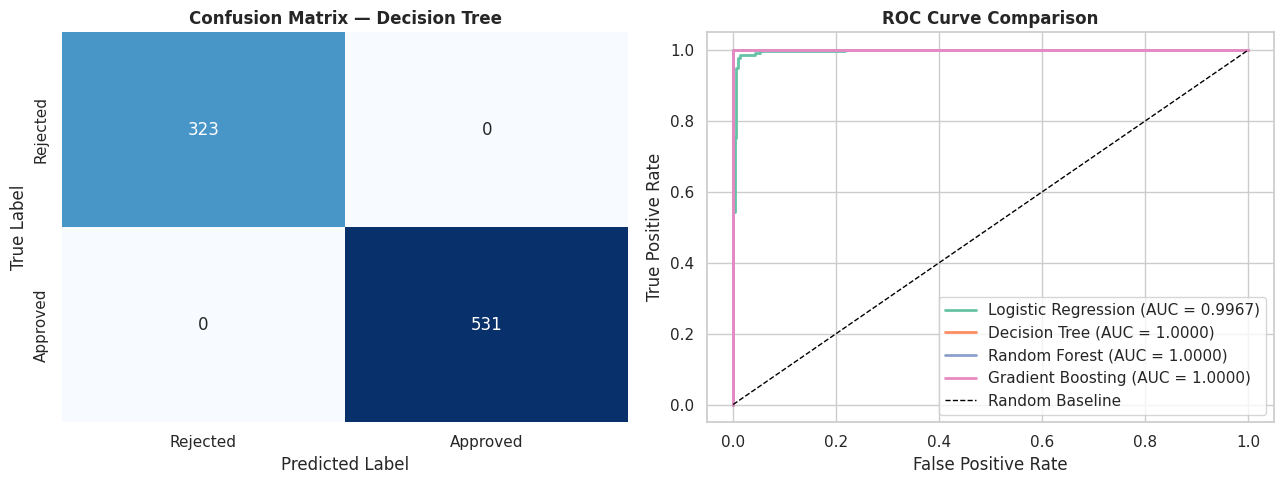

In [13]:
# Confusion Matrix (Best Model) & ROC Curves (All Models)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, predictions[best_model_name])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Rejected', 'Approved'],
            yticklabels=['Rejected', 'Approved'], ax=axes[0])
axes[0].set_title(f'Confusion Matrix — {best_model_name}', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curves
for name in trained_pipelines:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_val = roc_auc_score(y_test, probabilities[name])
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.4f})")

axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Baseline')
axes[1].set_title('ROC Curve Comparison', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## Step 12: Interpret
Inspect what drives loan approval decisions using both **Built-in Feature Importances** and **Permutation Importance** on the test set.

Top 5 Most Influential Features (Permutation Importance):
             Feature  Perm_Importance_Mean  Perm_Importance_Std
      cibil_category                0.3423               0.0097
 emi_to_income_ratio                0.0408               0.0032
loan_to_income_ratio                0.0170               0.0021
loan_to_assets_ratio                0.0055               0.0013
 luxury_assets_value                0.0000               0.0000


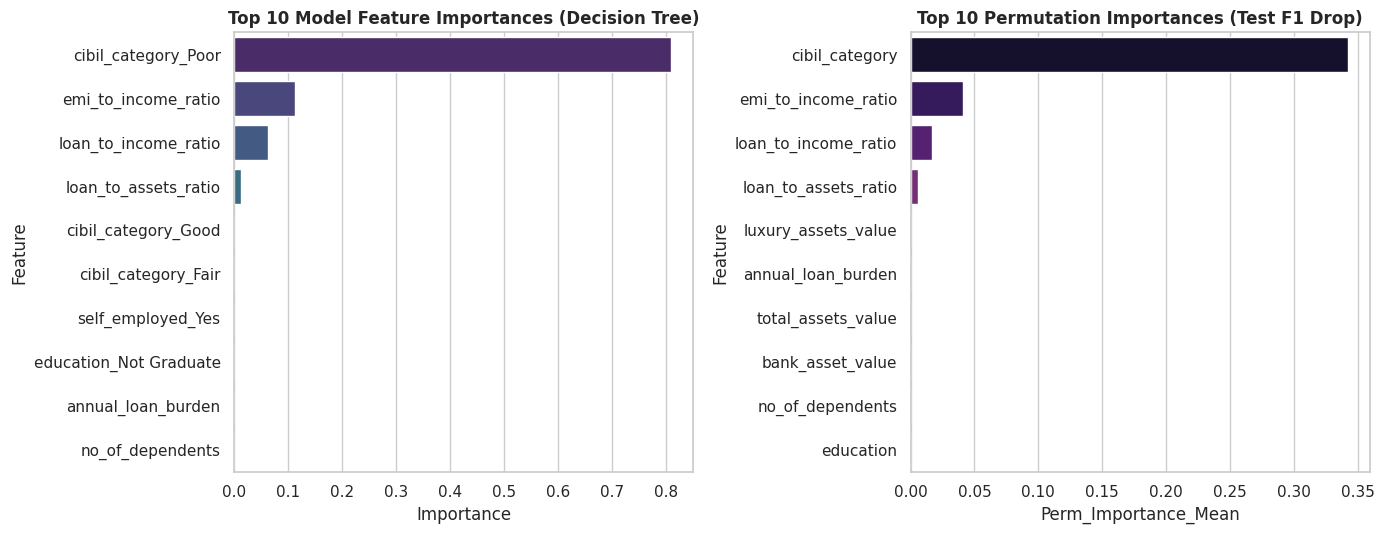

In [14]:
# 12.1 Built-in Feature Importances (Best Tree Model)
clf_step = best_pipeline.named_steps['classifier']
prep_step = best_pipeline.named_steps['preprocessor']
feat_names = [f.replace('num__', '').replace('cat__', '') for f in prep_step.get_feature_names_out()]

if hasattr(clf_step, 'feature_importances_'):
    importances = clf_step.feature_importances_
else:
    importances = np.abs(clf_step.coef_[0])

fi_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances}).sort_values('Importance', ascending=False)

# 12.2 Permutation Importance on raw X_test
perm = permutation_importance(best_pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring='f1')
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Perm_Importance_Mean': perm.importances_mean,
    'Perm_Importance_Std': perm.importances_std
}).sort_values('Perm_Importance_Mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=fi_df.head(10), x='Importance', y='Feature', ax=axes[0], palette='viridis')
axes[0].set_title(f'Top 10 Model Feature Importances ({best_model_name})', fontweight='bold')

sns.barplot(data=perm_df.head(10), x='Perm_Importance_Mean', y='Feature', ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Permutation Importances (Test F1 Drop)', fontweight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Most Influential Features (Permutation Importance):")
print(perm_df.head(5).round(4).to_string(index=False))

## Step 13: Validate
Verify model stability and check for overfitting using **5-Fold Stratified Cross-Validation** across all models.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}

cv_rows = []
for name, clf in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'Train_F1': scores['train_f1'].mean(),
        'CV_F1_Mean': scores['test_f1'].mean(),
        'CV_F1_Std': scores['test_f1'].std(),
        'CV_Acc_Mean': scores['test_accuracy'].mean(),
        'CV_AUC_Mean': scores['test_roc_auc'].mean(),
        'Overfit_Gap_F1': scores['train_f1'].mean() - scores['test_f1'].mean()
    })

cv_df = pd.DataFrame(cv_rows).sort_values('CV_F1_Mean', ascending=False).reset_index(drop=True)
print("5-Fold Stratified Cross-Validation Results:")
print(cv_df.round(4).to_string(index=False))

5-Fold Stratified Cross-Validation Results:
              Model  Train_F1  CV_F1_Mean  CV_F1_Std  CV_Acc_Mean  CV_AUC_Mean  Overfit_Gap_F1
  Gradient Boosting    1.0000      0.9995     0.0006       0.9994       0.9995          0.0005
      Decision Tree    1.0000      0.9993     0.0009       0.9991       0.9988          0.0007
      Random Forest    1.0000      0.9981     0.0019       0.9977       1.0000          0.0019
Logistic Regression    0.9778      0.9761     0.0072       0.9704       0.9957          0.0017


## Step 14: Save Artifacts
Save the best trained pipeline (`joblib`), model metadata (`json`), and test set predictions (`csv`) for deployment and reproducibility.

In [16]:
MODEL_FILE = 'loan_approval_best_model.joblib'
META_FILE = 'model_metadata.json'
PRED_FILE = 'test_predictions.csv'

# 1. Save trained pipeline
joblib.dump(best_pipeline, MODEL_FILE)

# 2. Save metadata
best_row = results_df.loc[0].to_dict()
metadata = {
    'best_model_name': best_model_name,
    'label_mapping': LABEL_MAP,
    'raw_input_features': [c for c in df_raw.columns.str.strip() if c not in ['loan_id', 'loan_status']],
    'model_features': X.columns.tolist(),
    'test_metrics': {k: round(float(v), 4) for k, v in best_row.items() if k != 'Model'}
}
with open(META_FILE, 'w') as f:
    json.dump(metadata, f, indent=2)

# 3. Save test predictions
out_preds = X_test.copy()
out_preds['actual_status'] = y_test.map(INV_LABEL_MAP)
out_preds['predicted_status'] = pd.Series(predictions[best_model_name], index=X_test.index).map(INV_LABEL_MAP)
out_preds['approval_probability'] = np.round(probabilities[best_model_name], 4)
out_preds.to_csv(PRED_FILE, index=False)

print(f"Saved model artifact:     {MODEL_FILE} ({os.path.getsize(MODEL_FILE)/1024:.1f} KB)")
print(f"Saved metadata artifact:  {META_FILE}")
print(f"Saved test predictions:   {PRED_FILE} ({len(out_preds)} rows)")

Saved model artifact:     loan_approval_best_model.joblib (8.0 KB)
Saved metadata artifact:  model_metadata.json
Saved test predictions:   test_predictions.csv (854 rows)


## Step 15: Demo Prediction
Reload the saved model artifact from disk and run live predictions on three new applicant profiles (Strong, Risky, and Borderline).

In [17]:
# Reload saved model and metadata
loaded_model = joblib.load(MODEL_FILE)
with open(META_FILE, 'r') as f:
    loaded_meta = json.load(f)

def predict_loan_approval(applicant: dict) -> dict:
    # Convert single applicant dict to DataFrame and apply identical cleaning + feature engineering
    df_new = pd.DataFrame([applicant])
    for col in df_new.select_dtypes(include='object').columns:
        df_new[col] = df_new[col].str.strip()
    df_new['residential_assets_value'] = df_new['residential_assets_value'].clip(lower=0)
    df_new = add_engineered_features(df_new)

    pred_class = int(loaded_model.predict(df_new)[0])
    prob_approved = float(loaded_model.predict_proba(df_new)[0, 1])

    return {
        'Decision': INV_LABEL_MAP[pred_class],
        'Approval_Probability': f"{prob_approved * 100:.2f}%",
        'CIBIL_Score': applicant['cibil_score'],
        'Loan_to_Income': round(applicant['loan_amount'] / applicant['income_annum'], 2)
    }

demo_applicants = [
    {
        'Profile': 'Strong Applicant',
        'no_of_dependents': 1, 'education': 'Graduate', 'self_employed': 'No',
        'income_annum': 8500000, 'loan_amount': 15000000, 'loan_term': 10,
        'cibil_score': 790, 'residential_assets_value': 12000000,
        'commercial_assets_value': 6000000, 'luxury_assets_value': 15000000,
        'bank_asset_value': 7000000
    },
    {
        'Profile': 'Risky Applicant',
        'no_of_dependents': 4, 'education': 'Not Graduate', 'self_employed': 'Yes',
        'income_annum': 2200000, 'loan_amount': 18000000, 'loan_term': 18,
        'cibil_score': 410, 'residential_assets_value': 1000000,
        'commercial_assets_value': 500000, 'luxury_assets_value': 2000000,
        'bank_asset_value': 400000
    },
    {
        'Profile': 'Borderline Applicant',
        'no_of_dependents': 2, 'education': 'Graduate', 'self_employed': 'Yes',
        'income_annum': 5000000, 'loan_amount': 14000000, 'loan_term': 4,
        'cibil_score': 555, 'residential_assets_value': 5000000,
        'commercial_assets_value': 3000000, 'luxury_assets_value': 10000000,
        'bank_asset_value': 3500000
    }
]

demo_results = []
for app in demo_applicants:
    profile_name = app.pop('Profile')
    res = predict_loan_approval(app)
    res['Profile'] = profile_name
    demo_results.append(res)

demo_df = pd.DataFrame(demo_results)[['Profile', 'CIBIL_Score', 'Loan_to_Income', 'Approval_Probability', 'Decision']]
print("Live Demo Predictions (Using Reloaded Model Artifact):")
print(demo_df.to_string(index=False))

Live Demo Predictions (Using Reloaded Model Artifact):
             Profile  CIBIL_Score  Loan_to_Income Approval_Probability Decision
    Strong Applicant          790            1.76              100.00% Approved
     Risky Applicant          410            8.18                0.00% Rejected
Borderline Applicant          555            2.80              100.00% Approved
